# TP 3- Clasificación multiclase de texto con Multilayer Perceptron + Regularización
### Redes Neuronales para Bioingeniería

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Consigna
A partir de las recomendaciones y los conceptos teóricos abordados durante las clases de regularización, se deberán incorporar y evaluar las siguientes estrategias como posibles hiperparámetros en el Trabajo Práctico de Clasificación de **20 Newsgroups (TNG)**:

- **Regularización L1 y L2**, tanto individualmente como en combinación (L1 + L2).
- **Dropout**.
- **Batch Normalization**.

Para cada estrategia, se deberán realizar experimentos considerando las recomendaciones discutidas en clase y analizar su impacto sobre el comportamiento y el desempeño del modelo.

El análisis deberá contemplar especialmente los siguientes aspectos:

- **Magnitud de los pesos:** observar los valores absolutos de los pesos de la red y analizar cómo se modifican según la estrategia de regularización aplicada.
- **Tiempos de entrenamiento:** comparar la duración de los entrenamientos y evaluar el impacto de cada estrategia sobre el costo computacional.
- **Learning Rate:** analizar la influencia de la tasa de aprendizaje y su interacción con las estrategias de regularización.
- **Curvas de aprendizaje:** observar la evolución de las métricas de entrenamiento y validación, prestando especial atención al ruido, las fluctuaciones y la estabilidad de las curvas.

Finalmente, se deberán **justificar e interpretar los fenómenos observados a partir de los fundamentos teóricos desarrollados en clase**, relacionando los resultados experimentales con el comportamiento esperado de cada técnica de regularización.

## 0. Setup

In [42]:
!pip install -q tensorboard
!pip install -q mlflow optuna
!pip install -q mlflow


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
!pip install nltk


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


c:\Users\Camila\Desktop\MLP_TNG_Escobar\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando dispositivo: cpu


In [45]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups


- Dataset: 20 Newsgroups (Scikit-learn), dividido en entrenamiento y prueba.

- Limpieza de metadatos: se aplicó remove=('headers', 'footers', 'quotes') para evitar data leakage (fuga de información) por datos triviales como nombres de categorías en encabezados.

- Variables clave: se extrajeron los textos planos (data), sus etiquetas numéricas (target), los nombres de clases (target_names) y el total de categorías a clasificar (NUM_CLASSES).

In [46]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

- Pipeline de limpieza: función preprocess_text que convierte a minúsculas, tokeniza (word_tokenize) y conserva solo tokens alfabéticos.

- Control de stopwords: opción remove_stopwords (True/False) para filtrar palabras vacías en inglés de baja carga semántica.

- Normalización: opción normalization para elegir entre "none", "stem" (PorterStemmer, truncamiento heurístico) o "lemmatize" (WordNetLemmatizer, reducción a lema de diccionario).

- Salida: reconstruye el texto procesado en un string separado por espacios, listo para vectorización.

In [47]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]

    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


Una vez armada la función de preprocesamiento, se prueban las 6 distintas configuraciones que surgen de seleccionar los parámetros de entrada de la función `preprocess_text`.

In [48]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

- Vectorización (TfidfVectorizer): transforma el texto preprocesado en matrices numéricas dispersas representando el peso $TF\text{-}IDF$ de cada término en el documento.
- Control del vocabulario: 
    - `ngram_range` controla si se utilizan unigramas (1,1) o si se agregan bigramas (1,2) para capturar contexto local.
    - `max_features`: define el tamaño máximo del vocabulario.
    - `min_df`: exige que un término aparezca en un mínimo de documentos para ser incluido, filtrando errores y términos atípicos.
- Prevención de data leakage: se aplica `.fit_transform()` únicamente sobre el conjunto de entrenamiento (train_texts) para construir el vocabulario, y sobre los datos de validación (test_texts) se ejecuta exclusivamente `.transform()`.

In [ ]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = vectorizer.fit_transform(train_texts) #FIT y TRANSFORM
    X_test = vectorizer.transform(test_texts) #SOLO TRANSFORM, NUNCA FIT.

    return X_train, X_test, vectorizer

In [50]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


## 4. Modelos: Regresión Softmax y MLP

- Modelo Regresión Softmax: implementa la arquitectura multiclase más simple mediante una única capa lineal (`nn.Linear`) que mapea la dimensión de entrada (input_dim) al número de clases (num_classes).
- Fórmula operativa: realiza la transformación $z = WX + \omega_0$, donde $W$ representa la matriz de pesos y $\omega_0$ el vector de sesgo (bias).
- Retorno de logits: la función `forward` devuelve los logits crudos sin aplicar la función Softmax explícitamente.
- Compatibilidad con PyTorch: se omite la activación final en el modelo debido a que la función de costo `nn.CrossEntropyLoss` combina internamente log_softmax y NLLLoss para optimizar la estabilidad numérica.

In [51]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)



In [52]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


### MLP
Para superar las limitaciones de la Regresión Softmax, que al ser un modelo lineal solo puede resolver problemas linealmente separables, implementamos un Perceptrón Multicapa (MLP, del inglés $Multilayer Perceptron$). 

La clave del MLP es que introduce capas ocultas con funciones de activación no lineales. Esto permite proyectar los datos de entrada a un espacio de mayor complejidad donde sí es posible trazar fronteras de decisión separables, respaldado por el Teorema de Aproximación Universal.  

Para poder probar distintas arquitecturas durante la exploración de hiperparámetros con Optuna, armamos la clase `MLPConfigurable`.

La inicialización incluye como parámetros de entrada:
- `ìnput_dim`: dimensión de los datos de entrada (vocabulario).
- `hidden_units`: cantidad de neuronas para cada una de las capas ocultas.
- `num_classes`: cantidad de clases a clasificar (20 para 20 Newsgroups).
- `activation_name`: define el tipo de función de activación no lineal a utilizar (sigmoidea, ReLU, tangente hiperbólica, etc).
  
A su vez, se incluye un diccionario con las distintas funciones de activaciones, mapeando la elección con la función correspondiente de PyTorch.

Luego se arman las capas:
- `nn.Linear(input_dim, neuronas)`: es la transformación $z = WX + \omega_0$ (multiplicación por matriz de pesos $W$ más el bias $\omega_0$). Convierte un espacio de tamaño input_dim a un espacio intermedio de tamaño neuronas.   
- `capas.append(f_act)`: añade la función no lineal seleccionada justo después de la capa lineal. Sin esta activación, la combinación de varias capas lineales colapsaría en una sola multiplicación lineal equivalente.   - `input_dim = neuronas`: reasigna la dimensión para que la siguiente capa sepa cuántas entradas recibir de la capa anterior.

Finalmente, se arma la última capa, con 20 salidas en este caso. `nn.Sequential(*capas)` toma la lista de capas y funciones de activación y las empaqueta en un solo bloque secuencial. 

In [53]:
class MLPConfigurable(nn.Module):
    def __init__(self, input_dim, hidden_units, num_classes, activation_name):
        """
        - input_dim: cantidad de features.
        - hidden_units: neuronas por capa.
        - num_classes: 20 (las 20 clases de 20Newsgroups)
        - activation_name: 'relu','sigmoid','tanh','elu','leaky_relu'
        """
        super().__init__()

        # 1. Selección de la función de activación
        activaciones = {
            "sigmoid": nn.Sigmoid(),
            "relu": nn.ReLU(),
            "tanh":nn.Tanh(),
            "elu": nn.ELU(),
            "leaky_relu": nn.LeakyReLU()
        }

        # Busca en activaciones y guarda la función de activación seleccionada
        f_act = activaciones[activation_name.lower()]

        capas=[]
        input_dim = input_dim #Guarda la dimensión de entrada de la capa.

        
        # 2. Armado de las capas ocultas (1, 2 o 3 capas)
        for neuronas in hidden_units:
            capas.append(nn.Linear(input_dim, neuronas)) # Capa de pesos
            capas.append(f_act)                          # Activación elegida
            input_dim = neuronas                         # Actualización de la cantidad de entradas para la capa siguiente
        
        # 3. Agregado de la capa de salida (20 clases)
        capas.append(nn.Linear(input_dim, num_classes))

        # 4. Empaquetado en una sola secuencia
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

## 5. Entrenamiento 

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

**DETALLE DEL BLOQUE**

La función `to_tensor_dataset` convierte los datos TF-IDF y sus etiquetas a tensores de PyTorch y los agrupa en un `TensorDataset`.

La función `train_model` realiza el entrenamiento y validación del modelo durante las épocas indicadas mediante `for epoch in range(epochs)`. En cada época, `model.train()` coloca el modelo en modo entrenamiento y se inicializan los contadores para acumular la pérdida y las predicciones correctas.

Luego, se recorren los datos de entrenamiento mediante `train_loader`, que entrega los documentos en batches. Los datos se trasladan al dispositivo correspondiente (CPU o GPU) mediante `.to(device)`. Antes de calcular los nuevos gradientes, `optimizer.zero_grad()` elimina los gradientes de la iteración anterior.

A continuación, se realiza el *forward pass* mediante `logits = model(xb)`. Los datos de entrada pasan por la capa lineal del modelo y se obtienen los logits correspondientes a las 20 clases. Luego, `CrossEntropyLoss` compara estos logits con las etiquetas reales y calcula la pérdida (*loss*).

Con `loss.backward()` se realiza el *backpropagation*, mediante el cual PyTorch calcula los gradientes de los parámetros del modelo respecto de la pérdida. Luego, `optimizer.step()` utiliza estos gradientes para actualizar los pesos y el bias del modelo, buscando reducir el error en las siguientes iteraciones.

Durante el entrenamiento también se acumulan las pérdidas y las predicciones correctas para calcular `train_loss` y `train_acc` al finalizar la época. La clase predicha se obtiene mediante `logits.argmax(dim=1)`, que selecciona el logit de mayor valor.

Una vez terminado el entrenamiento de la época, el modelo pasa a modo testeo mediante `model.eval()`. Se recorren los datos de validación sin modificar los parámetros del modelo. El bloque `torch.no_grad()` evita el cálculo de gradientes, ya que durante la validación no se realizan actualizaciones. De esta manera se calculan `val_loss` y `val_acc`, que permiten evaluar cómo generaliza el modelo sobre datos que no utiliza para ajustar sus pesos.

Finalmente, los valores de pérdida y accuracy de entrenamiento y validación se almacenan en `history`. Además, se registran en TensorBoard y MLflow para poder visualizar y comparar la evolución de los distintos entrenamientos.

ACLARACIÓN: esta función define cómo se entrena el modelo al ingresar un modelo, datos, un optimizador y una cantidad de épocas, pero aún no se está realizando el entrenamiento en sí mismo.

# ===========================================================
### NUEVO:

Nota de diseño: la función train_model se diseñó de forma genérica y modular. Dado que tanto la regresión Softmax como el perceptrón multicapa (MLP) reciben tensores con las características TF-IDF y devuelven los logits de las 20 clases objetivo, esta misma función abstrae el bucle de entrenamiento, validación y registro de métricas (TensorBoard/MLflow) para ambos modelos sin necesidad de duplicar código.

In [54]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="experiment",trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

        # ------------------------------------------------------------------------
        # PRUNING DE OPTUNA
        # ------------------------------------------------------------------------
        if trial is not None:
            trial.report(val_acc, step=epoch) # Trial reporta a Optuna su accuracy
 
            # Si Optuna decide podar, interrumpe la ejecución de este trial
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    return history


## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).


**DETALLE DEL BLOQUE**

En este bloque se utiliza **Optuna** para buscar una configuración de hiperparámetros que permita obtener el mejor desempeño del modelo. Un *trial* representa un entrenamiento realizado con una determinada combinación de hiperparámetros.

Primero se precalculan las 6 combinaciones posibles de preprocesamiento, dadas por las dos opciones de eliminación de stopwords (`True` o `False`) y las tres opciones de normalización (`none`, `stem` o `lemmatize`). Estas combinaciones se guardan en `preprocessed_cache` para evitar repetir el preprocesamiento en cada prueba, ya que es la parte más lenta de pipeline.

Luego se define la función `objective`, que representa un experimento individual. En cada trial, Optuna selecciona automáticamente valores para los hiperparámetros:

* Eliminación de stopwords.
* Tipo de normalización.
* Uso de unigramas o bigramas.
* Cantidad máxima de palabras en el vocabulario (`max_features`).
* Frecuencia mínima de aparición de las palabras (`min_df`).
* Tasa de aprendizaje, learning rate (`lr`).
* Tamaño del batch (`batch_size`).

Para cada configuración se divide el conjunto de entrenamiento en un subconjunto de entrenamiento y otro de validación, manteniendo la proporción de las clases usando `stratify`. El conjunto de test no se utiliza durante esta búsqueda, ya que se reserva para la evaluación final.

Después se vectorizan los textos mediante TF-IDF, se crean los `DataLoader` y se construye un nuevo modelo de Regresión Softmax. El modelo se entrena durante 5 épocas utilizando el optimizador Adam y la tasa de aprendizaje seleccionada por Optuna.

Al finalizar cada trial, se devuelve el `val_acc` de la última época. Optuna utiliza este valor como objetivo para comparar las diferentes configuraciones y, dado que `direction="maximize"`, busca maximizar la accuracy de validación.

Finalmente, `study.best_params` muestra la combinación de hiperparámetros que obtuvo el mejor resultado y `study.best_value` muestra la mejor accuracy de validación encontrada.

Así, Optuna permite automatizar la exploración de distintas configuraciones de hiperparámetros, en lugar de probar manualmente cada combinación.



In [55]:
def tracked(objective, prefix):
    def wrapper(trial):
        # nested=True permite abrir un Run hijo si ya existe un Run activo
        with mlflow.start_run(run_name=f"{prefix}_trial_{trial.number}", nested=True):
            try:
                return objective(trial)
            finally:
                mlflow.log_params(trial.params)
    return wrapper

In [56]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [57]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}",trial=trial)

    return history["val_acc"][-1]

# Se agrega pruning de Optuna al modelo Softmax también.
study_softmax = optuna.create_study(
    direction="maximize",
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=2))
study_softmax.optimize(tracked(objective, "softmax"), n_trials=15)

print("Mejores hiperparámetros:", study_softmax.best_params)
print("Mejor accuracy de validación:", study_softmax.best_value)


[I 2026-10-21 00:29:45,477] A new study created in memory with name: no-name-eaca91fc-680e-4558-abf3-cf5395bbe936


[trial_0] Epoch 1/5 - train_loss: 2.1407 train_acc: 0.5817 - val_loss: 1.5784 val_acc: 0.6845
[trial_0] Epoch 2/5 - train_loss: 1.0885 train_acc: 0.8369 - val_loss: 1.2610 val_acc: 0.6960
[trial_0] Epoch 3/5 - train_loss: 0.7429 train_acc: 0.8868 - val_loss: 1.1425 val_acc: 0.6969
[trial_0] Epoch 4/5 - train_loss: 0.5619 train_acc: 0.9156 - val_loss: 1.0894 val_acc: 0.6991


[I 2026-10-21 00:29:52,924] Trial 0 finished with value: 0.694653115333628 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 1, 'lr': 0.011227886666969939, 'batch_size': 32}. Best is trial 0 with value: 0.694653115333628.


[trial_0] Epoch 5/5 - train_loss: 0.4493 train_acc: 0.9347 - val_loss: 1.0624 val_acc: 0.6947
[trial_1] Epoch 1/5 - train_loss: 1.4889 train_acc: 0.5641 - val_loss: 1.2182 val_acc: 0.6412
[trial_1] Epoch 2/5 - train_loss: 0.3243 train_acc: 0.9205 - val_loss: 1.2572 val_acc: 0.6341
[trial_1] Epoch 3/5 - train_loss: 0.1666 train_acc: 0.9671 - val_loss: 1.3073 val_acc: 0.6323
[trial_1] Epoch 4/5 - train_loss: 0.1285 train_acc: 0.9717 - val_loss: 1.3559 val_acc: 0.6235


[I 2026-10-21 00:29:59,670] Trial 1 finished with value: 0.62129916040654 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 5, 'lr': 0.07279664046091076, 'batch_size': 32}. Best is trial 0 with value: 0.694653115333628.


[trial_1] Epoch 5/5 - train_loss: 0.1139 train_acc: 0.9726 - val_loss: 1.3748 val_acc: 0.6213
[trial_2] Epoch 1/5 - train_loss: 2.6730 train_acc: 0.4955 - val_loss: 2.3845 val_acc: 0.6160
[trial_2] Epoch 2/5 - train_loss: 2.0874 train_acc: 0.7252 - val_loss: 2.0015 val_acc: 0.6434
[trial_2] Epoch 3/5 - train_loss: 1.7068 train_acc: 0.7636 - val_loss: 1.7556 val_acc: 0.6536
[trial_2] Epoch 4/5 - train_loss: 1.4473 train_acc: 0.7852 - val_loss: 1.5922 val_acc: 0.6580


... (22 outputs left out)

[I 2026-10-21 00:31:04,584] Trial 13 finished with value: 0.7313300927971719 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'lr': 0.012132321749090723, 'batch_size': 64}. Best is trial 13 with value: 0.7313300927971719.


[trial_13] Epoch 5/5 - train_loss: 0.4812 train_acc: 0.9428 - val_loss: 1.0538 val_acc: 0.7313
[trial_14] Epoch 1/5 - train_loss: 2.6622 train_acc: 0.5424 - val_loss: 2.3287 val_acc: 0.6721
[trial_14] Epoch 2/5 - train_loss: 1.9123 train_acc: 0.8380 - val_loss: 1.9060 val_acc: 0.6991
[trial_14] Epoch 3/5 - train_loss: 1.4431 train_acc: 0.8864 - val_loss: 1.6461 val_acc: 0.7123
[trial_14] Epoch 4/5 - train_loss: 1.1389 train_acc: 0.9062 - val_loss: 1.4810 val_acc: 0.7172


[I 2026-10-21 00:31:11,239] Trial 14 finished with value: 0.7154220061864781 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.0077794545626802, 'batch_size': 128}. Best is trial 13 with value: 0.7313300927971719.


[trial_14] Epoch 5/5 - train_loss: 0.9327 train_acc: 0.9191 - val_loss: 1.3707 val_acc: 0.7154
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'lr': 0.012132321749090723, 'batch_size': 64}
Mejor accuracy de validación: 0.7313300927971719


## NUEVO
Adaptación y agregados para búsqueda de hiperparámetros en MLP:
1. Exploración dinámica de la arquitectura de red:
    - Profundidad (`num_layers`): Optuna elige entre 1, 2 o 3 capas ocultas. 
    - Ancho por capa (`hidden_units`): mediante un bucle for, define independientemente la cantidad de neuronas para cada capa previa (units_layer_i), evaluando entre 64, 128, 256 y 512 unidades.
    - Funciones de activación (activation): explora de forma categórica la función no lineal a utilizar (relu, sigmoid, tanh, elu, leaky_relu).
2. Selección y configuración dinámica del optimizador: ya no se limita a usar un único optimizador fijo; ahora prueba entre Adam, RMSprop y SGD (Softmax usaba solo Adam). 
    - Optimización de hiperparámetros internos de los optimizadores:
        - Adam: optimiza los momentos de orden 1 (beta1 entre 0.8 y 0.99) y orden 2 (beta2 entre 0.9 y 0.9999).
        - RMSprop: ajusta la tasa de decaimiento del promedio móvil (alpha) y el parámetro de impulso (momentum).
        - SGD: explora el valor óptimo de impulso (momentum).

3. Estrategia de pruning early stopping (MedianPruner): se incorporó el podador de Optuna (optuna.pruners.MedianPruner(n_warmup_steps=2)), que evalúa en tiempo real la accuracy de validación durante las épocas. Si en la época 2 o posterior el trial rinde por debajo de la mediana de todas las corridas anteriores, Optuna interrumpe (poda) el entrenamiento inmediatamente. Esto ahorra tiempo de cómputo evitando terminar entrenamientos poco prometedores.
   
4. Instanciación modular: se invoca a la clase MLPConfigurable pasándole la lista construida de hidden_units y la función de activación seleccionada para adaptar la red al paso actual.

In [58]:
def objective_mlp(trial):
    # -------------------------------------------------------------------------
    # 1. Hiperparámetros de Preprocesamiento de Texto (reusando preprocessed_cache)
    # -------------------------------------------------------------------------
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    # -------------------------------------------------------------------------
    # 2. Hiperparámetros de Entrenamiento General
    # -------------------------------------------------------------------------
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # -------------------------------------------------------------------------
    # 3. Hiperparámetros de la Arquitectura MLP (Capas, Neuronas y Activación)
    # -------------------------------------------------------------------------
    num_layers = trial.suggest_int("num_layers", 1, 3)
    hidden_units = []
    for i in range(num_layers):
        units = trial.suggest_categorical(f"units_layer_{i}", [64, 128, 256, 512])
        hidden_units.append(units)
        
    activation_name = trial.suggest_categorical("activation", ["relu", "sigmoid", "tanh", "elu", "leaky_relu"])

    # -------------------------------------------------------------------------
    # 4. Hiperparámetros de Optimizador y Momentos de Orden 1 y 2
    # -------------------------------------------------------------------------
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])

    # -------------------------------------------------------------------------
    # 5. Carga de Datos, Split y Vectorización TF-IDF
    # -------------------------------------------------------------------------
    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, 
        newsgroups_train.target, 
        test_size=0.2, 
        random_state=SEED,
        stratify=newsgroups_train.target
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # -------------------------------------------------------------------------
    # 6. Instanciación del Modelo MLPConfigurable
    # -------------------------------------------------------------------------
    model = MLPConfigurable(
        input_dim=X_tr.shape[1],
        hidden_units=hidden_units,
        num_classes=NUM_CLASSES,
        activation_name=activation_name
    )

    # -------------------------------------------------------------------------
    # 7. Selección del Optimizador y Momentos Específicos
    # -------------------------------------------------------------------------
    if optimizer_name == "Adam":
        # Orden 1: beta1, Orden 2: beta2
        lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)
        optimizer = optim.Adam(
            model.parameters(), 
            lr=lr, 
            betas=(beta1, beta2)
        )

    elif optimizer_name == "RMSprop":
        # Orden 2: alpha, Orden 1: momentum
        lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
        alpha = trial.suggest_float("rmsprop_alpha", 0.8, 0.99)
        momentum = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
        optimizer = optim.RMSprop(
            model.parameters(), 
            lr=lr, 
            alpha=alpha, 
            momentum=momentum
        )

    else:  # SGD
        # Orden 1: momentum
        lr_sgd = trial.suggest_float("lr_sgd", 1e-2, 1.0, log=True) # Se le da a SGD un rango de lr propio para hacer pasos de gradiente más grandes y competir en igualdad de condiciones con los otros optimizadores.
        momentum = trial.suggest_float("sgd_momentum", 0.0, 0.9)
        optimizer = optim.SGD(
            model.parameters(), 
            lr=lr_sgd, 
            momentum=momentum
        )

    # -------------------------------------------------------------------------
    # 8. Entrenamiento con la función genérica (run_name="experiment" por defecto)
    # -------------------------------------------------------------------------
    history = train_model(
        model=model, 
        train_loader=train_loader, 
        val_loader=val_loader, 
        optimizer=optimizer, 
        epochs=5, 
        run_name=f"mlp_trial_{trial.number}",
        trial=trial
    )

    # Optuna maximiza la métrica de accuracy en el conjunto de validación de la última época
    return history["val_acc"][-1]


# ----------------------------------------------------------------------------
# 9. Lanzamiento de la búsqueda
# ----------------------------------------------------------------------------
study_mlp = optuna.create_study(
    direction="maximize",
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)    
    )
# MedianPruner calcula la mediana de los resultados de todas las corridas anteriores en la misma época.
# Si el trial actual está por debajo de esa mediana, se asume que no se va a recuperar y se "poda".
# n_warmup_steps indica a partir de qué época es posible podar (se eligió la segunda).

study_mlp.optimize(tracked(objective_mlp,"mlp"), n_trials=15)

print("\n--- MEJORES RESULTADOS MLP ---")
print("Mejor Accuracy de Validación:", study_mlp.best_value)
print("Mejores Hiperparámetros:", study_mlp.best_params)

[I 2026-10-21 00:31:11,394] A new study created in memory with name: no-name-f1d14c06-214e-4347-b7f5-41649a168384


[mlp_trial_0] Epoch 1/5 - train_loss: 3.0068 train_acc: 0.0541 - val_loss: 3.0106 val_acc: 0.0526
[mlp_trial_0] Epoch 2/5 - train_loss: 3.0035 train_acc: 0.0489 - val_loss: 2.9979 val_acc: 0.0526
[mlp_trial_0] Epoch 3/5 - train_loss: 3.0016 train_acc: 0.0481 - val_loss: 2.9990 val_acc: 0.0526
[mlp_trial_0] Epoch 4/5 - train_loss: 2.9998 train_acc: 0.0475 - val_loss: 2.9983 val_acc: 0.0521


[I 2026-10-21 00:31:16,169] Trial 0 finished with value: 0.05302695536897923 and parameters: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 5, 'lr': 0.02021643544673734, 'batch_size': 128, 'num_layers': 3, 'units_layer_0': 512, 'units_layer_1': 128, 'units_layer_2': 64, 'activation': 'sigmoid', 'optimizer': 'SGD', 'lr_sgd': 0.3830017790557978, 'sgd_momentum': 0.08501206509385618}. Best is trial 0 with value: 0.05302695536897923.


[mlp_trial_0] Epoch 5/5 - train_loss: 2.9960 train_acc: 0.0516 - val_loss: 2.9948 val_acc: 0.0530
[mlp_trial_1] Epoch 1/5 - train_loss: 2.3424 train_acc: 0.2821 - val_loss: 1.7295 val_acc: 0.4397
[mlp_trial_1] Epoch 2/5 - train_loss: 1.2796 train_acc: 0.6004 - val_loss: 1.6053 val_acc: 0.5329
[mlp_trial_1] Epoch 3/5 - train_loss: 0.8686 train_acc: 0.7505 - val_loss: 1.8695 val_acc: 0.5453
[mlp_trial_1] Epoch 4/5 - train_loss: 0.6802 train_acc: 0.8152 - val_loss: 2.0253 val_acc: 0.5369


[I 2026-10-21 00:31:31,298] Trial 1 finished with value: 0.5457357490057446 and parameters: {'remove_stopwords': False, 'normalization': 'none', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 5, 'lr': 0.03567362950430961, 'batch_size': 128, 'num_layers': 3, 'units_layer_0': 512, 'units_layer_1': 256, 'units_layer_2': 128, 'activation': 'leaky_relu', 'optimizer': 'Adam', 'adam_beta1': 0.8066682920046667, 'adam_beta2': 0.9102464591867435}. Best is trial 1 with value: 0.5457357490057446.


[mlp_trial_1] Epoch 5/5 - train_loss: 0.6706 train_acc: 0.8543 - val_loss: 2.5507 val_acc: 0.5457
[mlp_trial_2] Epoch 1/5 - train_loss: 2.9897 train_acc: 0.0633 - val_loss: 2.9837 val_acc: 0.0738
[mlp_trial_2] Epoch 2/5 - train_loss: 2.9799 train_acc: 0.1102 - val_loss: 2.9747 val_acc: 0.2214
[mlp_trial_2] Epoch 3/5 - train_loss: 2.9681 train_acc: 0.1770 - val_loss: 2.9617 val_acc: 0.2099
[mlp_trial_2] Epoch 4/5 - train_loss: 2.9503 train_acc: 0.2194 - val_loss: 2.9403 val_acc: 0.2245


... (22 outputs left out)

[I 2026-10-21 00:33:29,168] Trial 13 pruned. 


[mlp_trial_13] Epoch 3/5 - train_loss: 1.7596 train_acc: 0.5326 - val_loss: 1.5938 val_acc: 0.5214
[mlp_trial_14] Epoch 1/5 - train_loss: 1.8812 train_acc: 0.4646 - val_loss: 1.0490 val_acc: 0.6885
[mlp_trial_14] Epoch 2/5 - train_loss: 0.6222 train_acc: 0.8178 - val_loss: 1.0054 val_acc: 0.7013
[mlp_trial_14] Epoch 3/5 - train_loss: 0.3038 train_acc: 0.9168 - val_loss: 1.1668 val_acc: 0.6911
[mlp_trial_14] Epoch 4/5 - train_loss: 0.1746 train_acc: 0.9550 - val_loss: 1.3406 val_acc: 0.6783


[I 2026-10-21 00:33:32,979] Trial 14 finished with value: 0.6681396376491383 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.04163949194320184, 'batch_size': 128, 'num_layers': 1, 'units_layer_0': 64, 'activation': 'sigmoid', 'optimizer': 'Adam', 'adam_beta1': 0.8036986168688933, 'adam_beta2': 0.9205327118205657}. Best is trial 14 with value: 0.6681396376491383.


[mlp_trial_14] Epoch 5/5 - train_loss: 0.1320 train_acc: 0.9650 - val_loss: 1.5791 val_acc: 0.6681

--- MEJORES RESULTADOS MLP ---
Mejor Accuracy de Validación: 0.6681396376491383
Mejores Hiperparámetros: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.04163949194320184, 'batch_size': 128, 'num_layers': 1, 'units_layer_0': 64, 'activation': 'sigmoid', 'optimizer': 'Adam', 'adam_beta1': 0.8036986168688933, 'adam_beta2': 0.9205327118205657}


## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

**DETALLE DEL BLOQUE**

Una vez que Optuna halló la mejor configuración de hiperparámetros, se realiza el entrenamiento final utilizando los mismos y el set entero de entrenamiento.

Primero se obtiene `study.best_params`, que contiene los valores de los hiperparámetros correspondientes al mejor trial.

Estos valores se guardan en variables como `BEST_REMOVE_SW`, `BEST_NORM`, `BEST_NGRAM`, `BEST_MAX_FEATURES`, `BEST_MIN_DF`, `BEST_LR` y `BEST_BATCH_SIZE`.

Luego, se recupera el preprocesamiento correspondiente y se aplica TF-IDF nuevamente sobre los conjuntos de entrenamiento y prueba utilizando los mejores parámetros encontrados. A partir de estos datos se crean los `DataLoader` para poder entrenar y evaluar el modelo por batches.

A continuación se crea un nuevo modelo desde cero. El tamaño del vocabulario de entrada se obtiene de `X_train_final.shape[1]`, mientras que la cantidad de clases es 20. También se crea el optimizador Adam utilizando la mejor tasa de aprendizaje encontrada por Optuna.

A diferencia de los trials de Optuna, que se entrenaron durante solo 5 épocas para poder probar muchas configuraciones en un tiempo razonable, el modelo final se entrena durante 20 épocas (`EPOCHS_FINAL = 20`).

Durante este entrenamiento se registran las métricas en **TensorBoard** mediante `SummaryWriter` y en **MLflow** mediante `mlflow.log_params` y las métricas registradas dentro de `train_model`. De esta manera, además de obtener el modelo final, se puede analizar la evolución del entrenamiento y conservar la configuración utilizada.

Finalmente, `mlflow.pytorch.log_model` guarda el modelo entrenado dentro de MLflow. El parámetro `input_example` proporciona un ejemplo del formato de entrada esperado por el modelo.

### Entrenamiento final Softmax


In [59]:
best_SM = study_softmax.best_params
BEST_REMOVE_SW_SM = best_SM["remove_stopwords"]
BEST_NORM_SM= best_SM["normalization"]
BEST_NGRAM_SM = (1, 1) if best_SM["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES_SM = best_SM["max_features"]
BEST_MIN_DF_SM = best_SM["min_df"]
BEST_LR_SM =  best_SM["lr"]
BEST_BATCH_SIZE_SM = best_SM["batch_size"]
EPOCHS_FINAL_SM = 20

train_texts_final_SM, test_texts_final_SM = preprocessed_cache[(BEST_REMOVE_SW_SM, BEST_NORM_SM)]
X_train_final_SM, X_test_final_SM, vectorizer_final__SM = vectorize_data(
    train_texts_final_SM, test_texts_final_SM, BEST_NGRAM_SM, BEST_MAX_FEATURES_SM, BEST_MIN_DF_SM
)

train_loader_final_SM = DataLoader(to_tensor_dataset(X_train_final_SM, newsgroups_train.target),
                                 batch_size=BEST_BATCH_SIZE_SM, shuffle=True)
test_loader_final_SM = DataLoader(to_tensor_dataset(X_test_final_SM, newsgroups_test.target),
                                batch_size=BEST_BATCH_SIZE_SM, shuffle=False)

model_SM= SoftmaxRegression(input_dim=X_train_final_SM.shape[1], num_classes=NUM_CLASSES)
optimizer_SM = optim.Adam(model_SM.parameters(), lr=BEST_LR_SM)
writer_SM = SummaryWriter(log_dir="runs/softmax_final")

mlflow.end_run()

mlflow.set_experiment("softmax_20newsgroups")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({
        "remove_stopwords": BEST_REMOVE_SW_SM, "normalization": BEST_NORM_SM,
        "ngram_range": str(BEST_NGRAM_SM), "max_features": BEST_MAX_FEATURES_SM, "min_df": BEST_MIN_DF_SM,
        "lr": BEST_LR_SM, "batch_size": BEST_BATCH_SIZE_SM, "epochs": EPOCHS_FINAL_SM,
    })
    history_softmax_final = train_model(model_SM, train_loader_final_SM, test_loader_final_SM, optimizer_SM,
                                   epochs=EPOCHS_FINAL_SM, writer=writer_SM, run_name="softmax_final", trial=None)
    mlflow.pytorch.log_model(model_SM, name="model", input_example=torch.randn(1,X_train_final_SM.shape[1]).numpy())

writer_SM.close()


[softmax_final] Epoch 1/20 - train_loss: 2.1835 train_acc: 0.6174 - val_loss: 1.7511 val_acc: 0.6579
[softmax_final] Epoch 2/20 - train_loss: 1.1172 train_acc: 0.8569 - val_loss: 1.4235 val_acc: 0.6680
[softmax_final] Epoch 3/20 - train_loss: 0.7481 train_acc: 0.9006 - val_loss: 1.2994 val_acc: 0.6707
[softmax_final] Epoch 4/20 - train_loss: 0.5604 train_acc: 0.9255 - val_loss: 1.2404 val_acc: 0.6718
[softmax_final] Epoch 5/20 - train_loss: 0.4460 train_acc: 0.9399 - val_loss: 1.2101 val_acc: 0.6690
[softmax_final] Epoch 6/20 - train_loss: 0.3694 train_acc: 0.9492 - val_loss: 1.1962 val_acc: 0.6668
[softmax_final] Epoch 7/20 - train_loss: 0.3147 train_acc: 0.9568 - val_loss: 1.1883 val_acc: 0.6642
[softmax_final] Epoch 8/20 - train_loss: 0.2743 train_acc: 0.9607 - val_loss: 1.1881 val_acc: 0.6613
[softmax_final] Epoch 9/20 - train_loss: 0.2435 train_acc: 0.9636 - val_loss: 1.1887 val_acc: 0.6591
[softmax_final] Epoch 10/20 - train_loss: 0.2194 train_acc: 0.9648 - val_loss: 1.1926 val_a

W1021 00:33:56.523000 32508 Lib\site-packages\torch\_export\non_strict_utils.py:825] dimension inputs[0].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.


In [60]:
best_ep_sm = int(np.argmax(history_softmax_final["val_acc"]))
print(f"Softmax | última época: {history_softmax_final['val_acc'][-1]:.4f} | "
      f"mejor época ({best_ep_sm+1}): {history_softmax_final['val_acc'][best_ep_sm]:.4f}")

Softmax | última época: 0.6472 | mejor época (4): 0.6718


### Entrenamiento final MLP

In [ ]:
# -----------------------------------------------------------------------------
# 1. EXTRACCIÓN DE MEJORES HIPERPARÁMETROS DEL MLP
# -----------------------------------------------------------------------------

best_mlp = study_mlp.best_params

BEST_REMOVE_SW_mlp = best_mlp["remove_stopwords"]
BEST_NORM_mlp = best_mlp["normalization"]
BEST_NGRAM_mlp = (1, 1) if best_mlp["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES_mlp = best_mlp["max_features"]
BEST_MIN_DF_mlp = best_mlp["min_df"]
BEST_BATCH_SIZE_mlp = best_mlp["batch_size"]
BEST_ACTIVATION_mlp = best_mlp["activation"]
BEST_OPT_NAME_mlp = best_mlp["optimizer"]

# Reconstrucción de la lista de neuronas por capa y número de capas.
hidden_units = [best_mlp[f"units_layer_{i}"] for i in range(best_mlp["num_layers"])]
EPOCHS_FINAL = 20

# -----------------------------------------------------------------------------
# 2. PREPROCESAMIENTO Y VECTORIZACIÓN (Dataset Completo)
# -----------------------------------------------------------------------------
train_texts_mlp, test_texts_mlp = preprocessed_cache[(BEST_REMOVE_SW_mlp, BEST_NORM_mlp)]

train_texts, val_texts, train_labels, val_labels = train_test_split(train_texts_mlp, 
                                                                 newsgroups_train.target,
                                                                 test_size = 0.2, # 20% del subset de Train,
                                                                 random_state=SEED,
                                                                 stratify=newsgroups_train.target # Misma proporción de categorías en ambos conjuntos
                                                                 )

X_train_mlp, X_val_mlp, vectorizer_mlp = vectorize_data(train_texts,
                                                        val_texts,
                                                        BEST_NGRAM_mlp,
                                                        BEST_MAX_FEATURES_mlp,
                                                        BEST_MIN_DF_mlp)

train_loader_mlp = DataLoader(
    to_tensor_dataset(X_train_mlp, train_labels),
    batch_size=BEST_BATCH_SIZE_mlp, shuffle=True
)
val_loader_mlp = DataLoader(
    to_tensor_dataset(X_val_mlp, val_labels),
    batch_size=BEST_BATCH_SIZE_mlp, shuffle=False
)

# -----------------------------------------------------------------------------
# 3. INSTANCIACIÓN DE ARQUITECTURA U OPTIMIZADOR
# -----------------------------------------------------------------------------
model_mlp_final = MLPConfigurable(
    input_dim=X_train_mlp.shape[1],
    hidden_units=hidden_units,
    num_classes=NUM_CLASSES,
    activation_name=BEST_ACTIVATION_mlp
)

# Configuración dinámica del optimizador según lo sugerido por Optuna
if BEST_OPT_NAME_mlp == "Adam":
    optimizer_mlp = optim.Adam(
        model_mlp_final.parameters(), 
        lr=best_mlp["lr"], 
        betas=(best_mlp["adam_beta1"], best_mlp["adam_beta2"])
    )
elif BEST_OPT_NAME_mlp == "RMSprop":
    optimizer_mlp = optim.RMSprop(
        model_mlp_final.parameters(), 
        lr=best_mlp["lr"],
        alpha=best_mlp["rmsprop_alpha"],
        momentum=best_mlp["rmsprop_momentum"]
    )
else:  # SGD
    optimizer_mlp = optim.SGD(
        model_mlp_final.parameters(), 
        lr=best_mlp["lr"], 
        momentum=best_mlp["sgd_momentum"]
    )
writer_mlp = SummaryWriter(log_dir="runs/mlp_final")

# -----------------------------------------------------------------------------
# 4. ENTRENAMIENTO Y REGISTRO EN MLFLOW
# -----------------------------------------------------------------------------
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups")

with mlflow.start_run(run_name="mlp_final"):
    # Guardamos todos los hiperparámetros encontrados por Optuna + épocas finales
    mlflow.log_params(best_mlp)
    mlflow.log_param("epochs", EPOCHS_FINAL)
    
    # Entrenamos sin pruning (trial=None)
    history_mlp_final = train_model(
        model=model_mlp_final,
        train_loader=train_loader_mlp,
        val_loader=val_loader_mlp,  # Evaluamos sobre validación
        optimizer=optimizer_mlp,
        epochs=EPOCHS_FINAL,
        writer=writer_mlp,
        run_name="mlp_final",
        trial=None
    )
    
    # Guardamos el artefacto del modelo en MLflow
    input_example = torch.randn(1, X_train_mlp.shape[1]).numpy()
    mlflow.pytorch.log_model(model_mlp_final, name="model", input_example=input_example)

writer_mlp.close()

print(f"\n=== Entrenamiento final del MLP completado ===")
print(f"Accuracy final en Validación: {history_mlp_final['val_acc'][-1]:.4f}")
print(f"Loss final en Validación: {history_mlp_final['val_loss'][-1]:.4f}")

# =================== PREPARACIÓN DEL CONJUNTO DE TEST ==============================

# Transformamos Test con el vectorizador ajustado durante el entrenamiento
X_test_mlp = vectorizer_mlp.transform(test_texts_mlp)

# Creamos el DataLoader de Test
test_loader_mlp = DataLoader(
    to_tensor_dataset(X_test_mlp, newsgroups_test.target),
    batch_size=BEST_BATCH_SIZE_mlp,
    shuffle=False
)

[mlp_final] Epoch 1/20 - train_loss: 1.7054 train_acc: 0.5107 - val_loss: 1.2437 val_acc: 0.6370
[mlp_final] Epoch 2/20 - train_loss: 0.5968 train_acc: 0.8178 - val_loss: 1.3699 val_acc: 0.6298
[mlp_final] Epoch 3/20 - train_loss: 0.3155 train_acc: 0.9110 - val_loss: 1.5490 val_acc: 0.6332
[mlp_final] Epoch 4/20 - train_loss: 0.1938 train_acc: 0.9457 - val_loss: 1.7977 val_acc: 0.6256
[mlp_final] Epoch 5/20 - train_loss: 0.1476 train_acc: 0.9610 - val_loss: 2.0162 val_acc: 0.6143
[mlp_final] Epoch 6/20 - train_loss: 0.1256 train_acc: 0.9662 - val_loss: 2.2242 val_acc: 0.6121
[mlp_final] Epoch 7/20 - train_loss: 0.1157 train_acc: 0.9684 - val_loss: 2.4087 val_acc: 0.6122
[mlp_final] Epoch 8/20 - train_loss: 0.1099 train_acc: 0.9699 - val_loss: 2.5188 val_acc: 0.6093
[mlp_final] Epoch 9/20 - train_loss: 0.1050 train_acc: 0.9717 - val_loss: 2.6621 val_acc: 0.6062
[mlp_final] Epoch 10/20 - train_loss: 0.1033 train_acc: 0.9711 - val_loss: 2.7023 val_acc: 0.6046
[mlp_final] Epoch 11/20 - tra

W1021 00:34:32.826000 32508 Lib\site-packages\torch\_export\non_strict_utils.py:825] dimension inputs[0].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.



=== Entrenamiento final del MLP completado ===
Accuracy final en Test: 0.5919
Loss final en Test: 3.5396


In [62]:
best_ep_mlp = int(np.argmax(history_mlp_final["val_acc"]))
print(f"MLP | última época: {history_mlp_final['val_acc'][-1]:.4f} | "
      f"mejor época ({best_ep_mlp+1}): {history_mlp_final['val_acc'][best_ep_mlp]:.4f}")

MLP | última época: 0.5919 | mejor época (1): 0.6370


Nótese que a partir de las primeras épocas, la Loss de entrenamiento cae rápidamente hacia valores cercanos a cero. Por otra parte, la Loss de validación comienza a subir a partir de la época 2. Esto es una señal clara de sobreajuste: el modelo memoriza el conjunto de entrenamiento y generaliza cada vez peor en términos de loss.

## 9. Evaluación final

**DETALLE DEL BLOQUE**

En este último bloque se evalúa el modelo final utilizando el set de test, que contiene datos que no se utilizaron para entrenar el modelo.

Primero, `model.eval()` coloca el modelo en modo validación y `torch.no_grad()` desactiva el cálculo de gradientes, ya que en esta etapa no deben modificarse los parámetros del modelo.

Luego, se recorren los datos de test por batches. Para cada batch, el modelo calcula los logits y mediante `argmax(dim=1)` se obtiene la clase predicha, seleccionando la clase con el mayor valor de salida. Las predicciones y las etiquetas reales se almacenan en `all_preds` y `all_labels`.

Una vez procesados todos los datos, `accuracy_score` calcula la accuracy sobre el conjunto de test, es decir, la proporción de documentos clasificados correctamente. Además, `classification_report` muestra métricas como precision, recall y F1-score para cada una de las 20 categorías, permitiendo analizar el desempeño del modelo tanto de manera global como para cada clase.

Por último, se construye una matriz de confusión utilizando las etiquetas reales y las predicciones. Las filas representan las clases reales y las columnas las clases predichas. Los valores de la diagonal corresponden a las clasificaciones correctas, mientras que los valores fuera de la diagonal representan confusiones entre diferentes categorías.

La matriz se visualiza mediante `plt.imshow()`, utilizando una escala de colores para facilitar la identificación de las clases en las que el modelo presenta mayor cantidad de aciertos o confusiones.


In [64]:
# Defino una función reutilizable para ambos modelos.

def evaluar_y_graficar_cm(model,test_loader,class_names,model_name="Modelo", device="cpu"):
    """
    Evalúa el modelo sobre el conjunto de test, imprime el classification_report
    y dibuja la matriz de confusión con Matplotlib.
    """
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(yb.numpy())

    test_accuracy = accuracy_score(all_labels, all_preds)
    print(f"==================================================")
    print(f" EVALUACIÓN DETALLADA: {model_name}")
    print(f" Accuracy en Test: {test_accuracy:.4f}")
    print(f"==================================================\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # Matriz de Confusión
    cm = confusion_matrix(all_labels, all_preds)
    
    plt.figure(figsize=(12, 10))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=90)
    plt.yticks(range(len(class_names)), class_names)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(f"Matriz de Confusión - {model_name}")
    plt.tight_layout()
    plt.show()
    
    return all_preds, all_labels



 EVALUACIÓN DETALLADA: Softmax Regression
 Accuracy en Test: 0.6472

                          precision    recall  f1-score   support

             alt.atheism       0.48      0.46      0.47       319
           comp.graphics       0.58      0.60      0.59       389
 comp.os.ms-windows.misc       0.58      0.56      0.57       394
comp.sys.ibm.pc.hardware       0.60      0.57      0.59       392
   comp.sys.mac.hardware       0.63      0.61      0.62       385
          comp.windows.x       0.72      0.65      0.69       395
            misc.forsale       0.75      0.77      0.76       390
               rec.autos       0.45      0.71      0.55       396
         rec.motorcycles       0.71      0.67      0.69       398
      rec.sport.baseball       0.81      0.76      0.78       397
        rec.sport.hockey       0.89      0.84      0.87       399
               sci.crypt       0.79      0.70      0.74       396
         sci.electronics       0.59      0.57      0.58       393
      

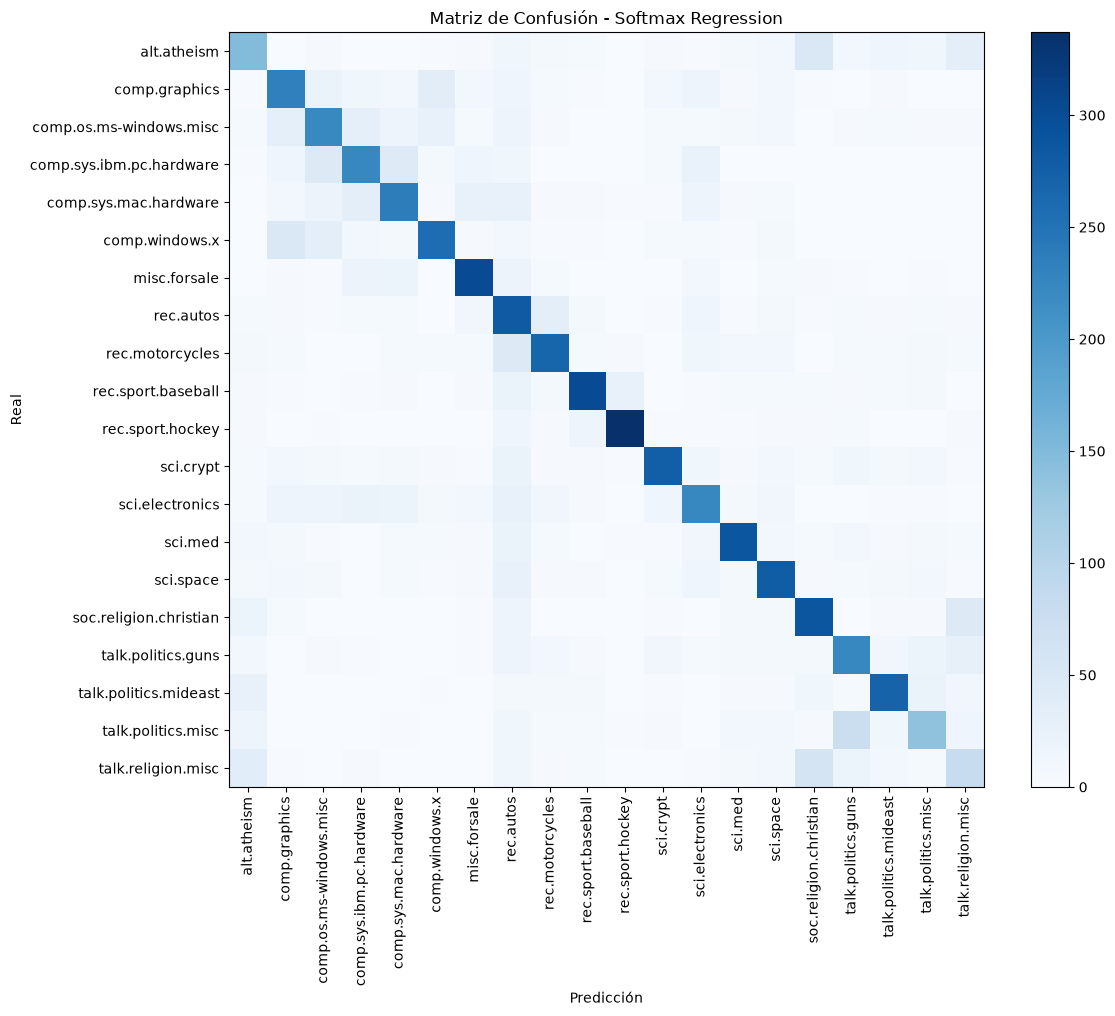

In [65]:
# Llamada para Softmax
preds_sm, labels_sm = evaluar_y_graficar_cm(
    model=model_SM, 
    test_loader=test_loader_final_SM, 
    class_names=newsgroups_train.target_names, 
    model_name="Softmax Regression",
    device=device
)

 EVALUACIÓN DETALLADA: MLP Optimizado
 Accuracy en Test: 0.5919

                          precision    recall  f1-score   support

             alt.atheism       0.37      0.50      0.43       319
           comp.graphics       0.50      0.52      0.51       389
 comp.os.ms-windows.misc       0.48      0.48      0.48       394
comp.sys.ibm.pc.hardware       0.54      0.55      0.55       392
   comp.sys.mac.hardware       0.70      0.50      0.59       385
          comp.windows.x       0.61      0.66      0.64       395
            misc.forsale       0.62      0.75      0.68       390
               rec.autos       0.40      0.67      0.50       396
         rec.motorcycles       0.75      0.57      0.65       398
      rec.sport.baseball       0.71      0.76      0.73       397
        rec.sport.hockey       0.85      0.82      0.84       399
               sci.crypt       0.69      0.66      0.68       396
         sci.electronics       0.46      0.53      0.49       393
          

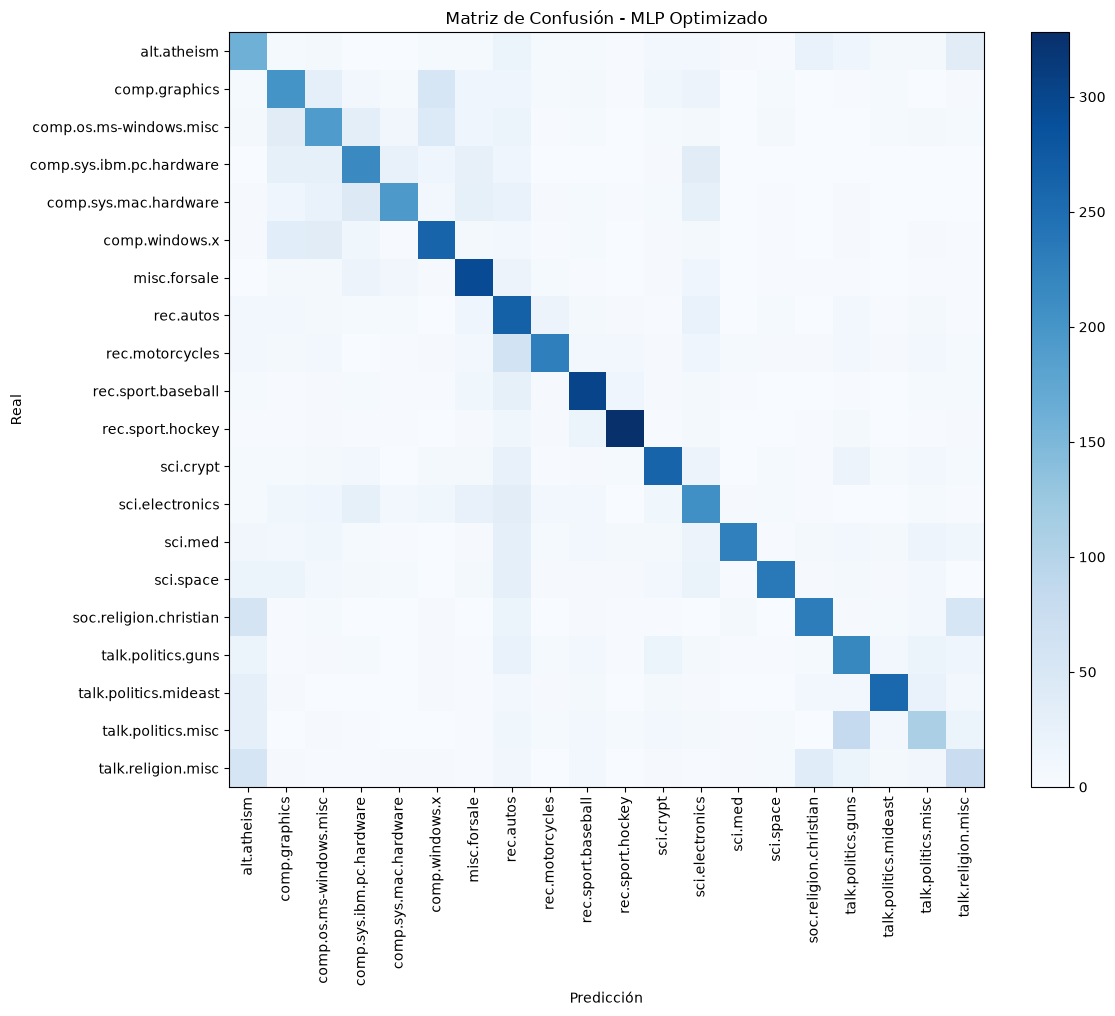

In [66]:
# Llamada para MLP
preds_mlp, labels_mlp = evaluar_y_graficar_cm(
    model=model_mlp_final, 
    test_loader=test_loader_mlp, 
    class_names=newsgroups_train.target_names, 
    model_name="MLP Optimizado",
    device=device
)

La regresión Softmax obtuvo mejores resultados que el MLP optimizado en el test: accuracy de 64,72 % frente a 59,19 % (5,5 puntos porcentuales de diferencia) y F1 macro de 0,64 frente a 0,59. La ventaja se mantiene aun comparando la mejor época de cada modelo (67,18 % contra 63,70 %), por lo que no se explica solo por el sobreentrenamiento del MLP.

Por categorías, ambos modelos rinden mejor en temas con vocabulario específico: `rec.sport.hockey` (F1 0,87 y 0,84), `rec.sport.baseball`, `sci.med`, `sci.crypt` y `talk.politics.mideast`. Rinden peor en categorías con vocabulario superpuesto: `talk.religion.misc` (0,33 y 0,30), `alt.atheism` y `talk.politics.misc`, que se confunden con otras clases de su mismo tema (religión y política). Las categorías `comp.*` quedan en un rango intermedio (0,5 a 0,7), también por compartir vocabulario. En `rec.autos` ambos modelos tienen recall alto pero precision baja (0,45 y 0,40), es decir que sobrepredicen esa clase. En casi todas las categorías Softmax supera al MLP.

In [14]:
from tensorboard import notebook

# Lista los procesos activos de TensorBoard
notebook.list()

# Inicia una instancia limpia apuntando a la carpeta de logs
notebook.start("--logdir runs --port 6030")

Known TensorBoard instances:
  - port 6008: logdir runs (started 2:02:42 ago; pid 31780)
  - port 6006: logdir runs (started 7:38:19 ago; pid 8640)


## 9. Análisis final y registros de TensorBoard y MLFlow

In [19]:
# Datos obtenidos con TensorBoard y MLflow (corrida final)
data = {
    "Modelo": ["Softmax Regression", "MLP Optimizado (Optuna)", "MLP Overfitting [512,512,512]"],
    "Run ID (MLflow)": ["072d8bed90c34be4b1039de888bc992f", "32fa2aed7ad643848f31ec854130b2a5", "N/A"],
    "Épocas": [20, 20, 30],
    "Duración total (MLflow)": ["35.6 s", "31.0 s", "N/A"],
    "Tiempo neto (TensorBoard)": ["18.3 s", "15.5 s", "N/A"],
    "Train Accuracy": [0.9715, 0.9728, 0.9624],
    "Val/Test Accuracy (última época)": [0.6472, 0.5919, 0.5908],
    "Val/Test Accuracy (mejor época)": [0.6718, 0.6370, 0.5969],
    "Train Loss": [0.1239, 0.0903, 0.1242],
    "Val/Test Loss": [1.2711, 3.5396, 3.4377],
}
df_resultados = pd.DataFrame(data)
df_resultados["Generalization Gap (Loss)"] = df_resultados["Val/Test Loss"] - df_resultados["Train Loss"]

df_display = df_resultados.copy()
for col in ["Train Accuracy", "Val/Test Accuracy (última época)", "Val/Test Accuracy (mejor época)"]:
    df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")
df_display["Generalization Gap (Loss)"] = df_display["Generalization Gap (Loss)"].apply(lambda x: f"{x:.4f}")

print(df_display.to_string(index=False))

                       Modelo                  Run ID (MLflow)  Épocas Duración total (MLflow) Tiempo neto (TensorBoard) Train Accuracy Val/Test Accuracy (última época) Val/Test Accuracy (mejor época)  Train Loss  Val/Test Loss Generalization Gap (Loss)
           Softmax Regression 072d8bed90c34be4b1039de888bc992f      20                  35.6 s                    18.3 s         97.15%                           64.72%                          67.18%      0.1239         1.2711                    1.1472
      MLP Optimizado (Optuna) 32fa2aed7ad643848f31ec854130b2a5      20                  31.0 s                    15.5 s         97.28%                           59.19%                          63.70%      0.0903         3.5396                    3.4493
MLP Overfitting [512,512,512]                              N/A      30                     N/A                       N/A         96.24%                           59.08%                          59.69%      0.1242         3.4377           

Para el seguimiento de las corridas se integraron las métricas registradas en **MLflow** junto con el monitoreo de los loops de entrenamiento mediante **TensorBoard**. La tabla anterior resume los resultados de ambas herramientas.

- Generalización: Softmax obtuvo 64,72 % en test y el MLP optimizado 59,19 %. Ambos llegan a ~97 % de accuracy en train, así que los dos sobreajustan. La diferencia está en cómo: el val_loss de Softmax se mantiene casi estable (1,27, con un mínimo de 1,19 en la época 8), mientras que el del MLP crece de forma sostenida desde la primera época (de 1,24 a 3,54). La brecha de loss es de 1,15 en Softmax contra 3,45 en el MLP. Como la accuracy del MLP cae solo unos puntos mientras su loss se triplica, el modelo se vuelve muy seguro de sus errores (sobreconfianza).

- Época óptima: Softmax alcanza su mejor accuracy en la época 4 (67,18 %) y el MLP en la época 1 (63,70 %). El MLP sobreajusta casi de inmediato, con un learning rate relativamente alto (0,042) y sin regularización. Estas cifras de "mejor época" se eligieron mirando el test, así que son un valor optimista.

- Tiempos: según MLflow, el entrenamiento final de Softmax duró 35,6 s y el del MLP 31,0 s, es decir que ambos tardaron un tiempo comparable y el MLP incluso fue algo más rápido. La duración de MLflow incluye el logging de métricas en cada época y el guardado del modelo (`log_model`), un costo fijo de unos 15 a 17 s en ambos casos que pesa mucho en un entrenamiento tan corto. El tiempo neto de entrenamiento medido por TensorBoard fue de 18,3 s para Softmax y 15,5 s para el MLP. Además, ambos modelos son pequeños: el MLP elegido por Optuna tiene una sola capa de 64 neuronas y usó batch size 128, mientras que Softmax usó batch size 64, es decir, el doble de iteraciones por época. En estos casos el tiempo depende más del número de iteraciones y del overhead que de la cantidad de parámetros. Se espera que el costo del MLP crezca con su tamaño (el sobredimensionado tiene ~3,1 millones de parámetros), pero ese run no se registró en MLflow.

**Causas.**
1. **Espacios de características dispersos:** la representación TF-IDF genera vectores de muy alta dimensión donde la gran mayoría de las entradas son cero. En este escenario las fronteras lineales, como las de Softmax, suelen funcionar bien.
2. **Parámetros adicionales innecesarios:** las capas ocultas multiplican la cantidad de parámetros. Sin regularización (dropout, weight decay, early stopping), el MLP tiende a memorizar coocurrencias raras de palabras del train en lugar de capturar la estructura general de las 20 categorías.



### Capturas de pantalla de TensorBoard

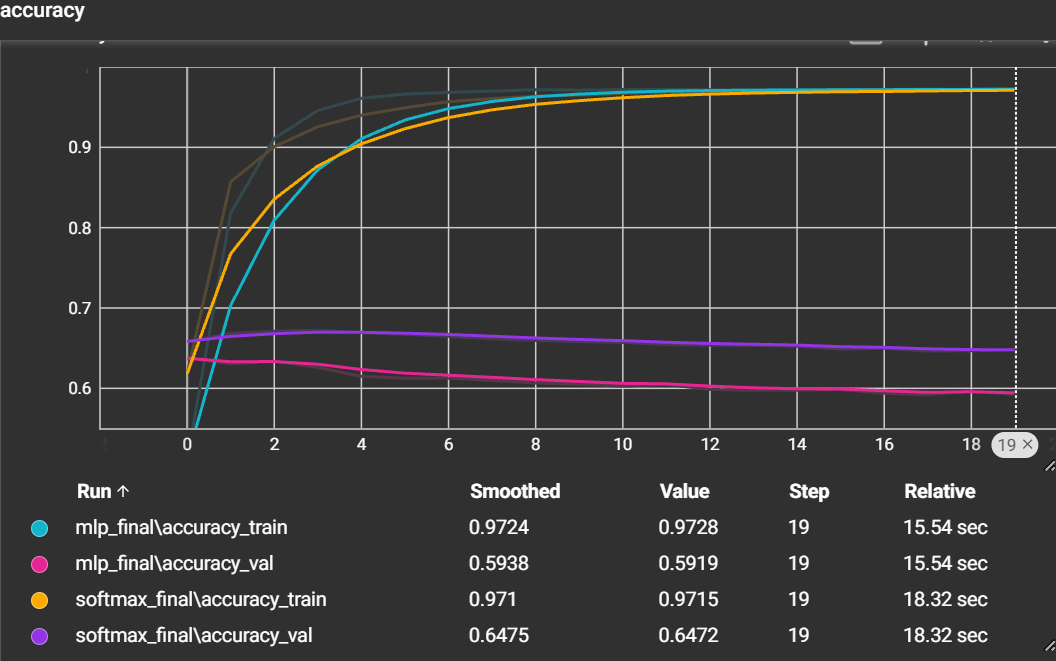


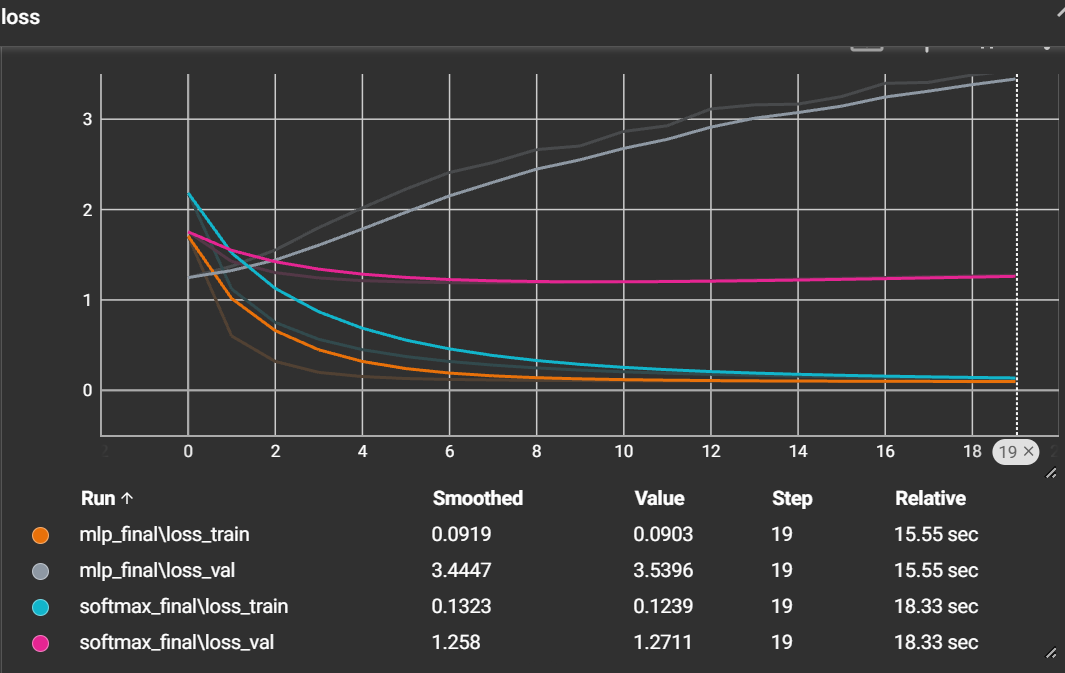

### Análisis de la búsqueda de hiperparámetros del MLP

De los 15 trials, 12 se completaron y 3 fueron podados. El mejor fue una red de **1 capa oculta de 64 neuronas, activación sigmoid y Adam**, con 66,8 % de accuracy de validación, por debajo del 73,1 % que logró Softmax en su búsqueda.

- **Optimizador:** Adam obtuvo la mejor media (59,3 %), seguido por RMSprop (52,3 %), y SGD quedó muy por detrás (20,4 %, máximo 46,4 %). Con solo 5 épocas, SGD no llegó a converger en varios trials (el trial 0, con SGD y sigmoid en 3 capas, quedó cerca del azar, ~5 %). Esto indica que SGD necesita más épocas o más ajuste del learning rate, no que sea intrínsecamente peor.
- **Capas:** 1 capa (52,1 %) y 2 capas (57,1 %) rindieron mejor que 3 capas (24,8 %), pero esta media está arrastrada por trials fallidos, por lo que no se concluye que más profundidad sea peor. El mejor resultado se obtuvo con 1 capa.
- **Activación:** hay entre 1 y 6 trials por función, así que no se puede concluir cuál es mejor.
- **Tiempo:** RMSprop fue el más lento en promedio (15,5 s) contra 6,9 s de Adam y 5,9 s de SGD, pero los tiempos dependen sobre todo del tamaño de la red y del batch size, que varían entre trials.
- **Pruning:** el podado evitó terminar 3 entrenamientos poco prometedores. Los trials podados cuentan con su última accuracy intermedia, medida antes de la época 5, por lo que las medias no son totalmente comparables.


In [20]:
# Resultados de la búsqueda de Optuna (corrida original), cargados a mano
# porque el estudio vivía en memoria y se perdió al reiniciar el kernel.
cols = pd.MultiIndex.from_product([["value", "duration_s"], ["mean", "max", "count"]])

def tabla(nombre, filas):
    df = pd.DataFrame(filas, columns=cols, index=pd.Index(list(filas.keys()), name=nombre))
    return df

print("state\nCOMPLETE    12\nPRUNED       3\n")

print(pd.DataFrame(
    [[0.593195, 0.668140, 5, 6.936762, 15.127544, 5],
     [0.522669, 0.658418, 5, 15.472071, 24.221088, 5],
     [0.204419, 0.463544, 5, 5.897993, 6.797029, 5]],
    columns=cols, index=pd.Index(["Adam", "RMSprop", "SGD"], name="params_optimizer")))

print(pd.DataFrame(
    [[0.142289, 0.160407, 2, 13.852445, 22.068800, 2],
     [0.492120, 0.642068, 6, 7.742124, 15.127544, 6],
     [0.608042, 0.608042, 1, 24.221088, 24.221088, 1],
     [0.459862, 0.668140, 3, 6.303586, 10.353598, 3],
     [0.458830, 0.620415, 3, 8.081551, 11.935435, 3]],
    columns=cols, index=pd.Index(["elu", "leaky_relu", "relu", "sigmoid", "tanh"], name="params_activation")))

print(pd.DataFrame(
    [[0.521432, 0.668140, 7, 9.659995, 24.221088, 7],
     [0.570776, 0.602298, 3, 6.500604, 8.781436, 3],
     [0.247813, 0.545736, 5, 10.882472, 22.068800, 5]],
    columns=cols, index=pd.Index([1, 2, 3], name="params_num_layers")))

state
COMPLETE    12
PRUNED       3

                     value                 duration_s                 
                      mean       max count       mean        max count
params_optimizer                                                      
Adam              0.593195  0.668140     5   6.936762  15.127544     5
RMSprop           0.522669  0.658418     5  15.472071  24.221088     5
SGD               0.204419  0.463544     5   5.897993   6.797029     5
                      value                 duration_s                 
                       mean       max count       mean        max count
params_activation                                                      
elu                0.142289  0.160407     2  13.852445  22.068800     2
leaky_relu         0.492120  0.642068     6   7.742124  15.127544     6
relu               0.608042  0.608042     1  24.221088  24.221088     1
sigmoid            0.459862  0.668140     3   6.303586  10.353598     3
tanh               0.458830  0.62